# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


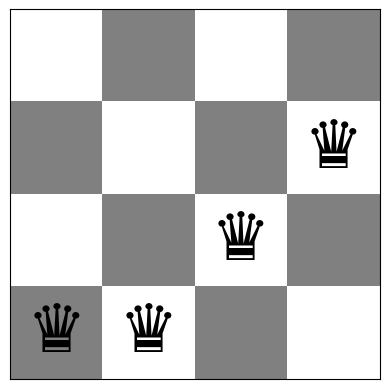

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


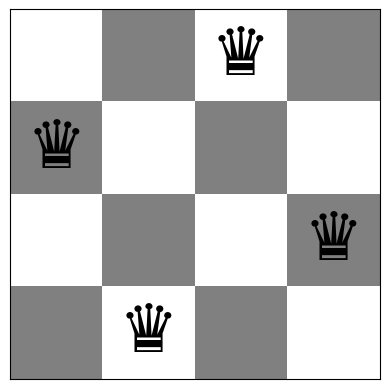

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

### Cài đặt dùng cho Bài 8

Ba biến thể HC dùng cùng hàm `conflicts` và toán tử chuyển một hậu sang hàng khác trong cột: n(n−1) hàng xóm. Steepest chọn bước giảm f nhiều nhất; Stochastic chọn đều trong mọi bước giảm f; First-choice lấy một hàng xóm ngẫu nhiên và chỉ nhận nếu giảm f. HC không nhận bước ngang bằng. Ngân sách được đếm bằng số lần đánh giá f, bao gồm bàn cờ ban đầu.

In [5]:
import random

def queen_moves(board, operator='any'):
    n = len(board)
    if operator == 'adjacent':
        return [(column, row) for column in range(n)
                for row in [board[column] - 1, board[column] + 1] if 0 <= row < n]
    return [(column, row) for column in range(n) for row in range(n) if row != board[column]]

def queens_hc(initial_board, mode='steepest', max_evals=5000, seed=0, operator='any'):
    rng = random.Random(seed)
    current = np.asarray(initial_board, dtype=int).copy()
    value = conflicts(current)
    evaluations = 1
    history = [value]
    failures = 0
    reason = 'budget'
    while value > 0 and evaluations < max_evals:
        if mode == 'first':
            if operator == 'any':
                column = rng.randrange(len(current))
                row = rng.randrange(len(current) - 1)
                row += row >= current[column]
                move_count = len(current) * (len(current) - 1)
            else:
                moves = queen_moves(current, operator)
                column, row = rng.choice(moves)
                move_count = len(moves)
            neighbor = current.copy()
            neighbor[column] = row
            new_value = conflicts(neighbor)
            evaluations += 1
            if new_value < value:
                current, value = neighbor, new_value
                failures = 0
            else:
                failures += 1
            history.append(value)
            if failures >= 5 * move_count:
                reason = 'patience'
                break
        else:
            moves = queen_moves(current, operator)
            if evaluations + len(moves) > max_evals:
                break
            improving = []
            for column, row in moves:
                neighbor = current.copy()
                neighbor[column] = row
                new_value = conflicts(neighbor)
                evaluations += 1
                if new_value < value:
                    improving.append((new_value, neighbor))
            if not improving:
                reason = 'local_minimum'
                history.append(value)
                break
            value, current = (min(improving, key=lambda item: item[0])
                              if mode == 'steepest' else rng.choice(improving))
            history.append(value)
    return {'best_board': current, 'best_f': value, 'current_history': np.asarray(history),
            'best_history': np.asarray(history), 'evaluations': evaluations,
            'steps': len(history) - 1, 'reason': 'solved' if value == 0 else reason}

def queens_steepest(board, max_evals=5000, seed=0):
    return queens_hc(board, 'steepest', max_evals, seed)

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [6]:
def queens_stochastic(board, max_evals=5000, seed=0):
    return queens_hc(board, 'stochastic', max_evals, seed)

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

Dừng First-choice sau 5m lần lấy mẫu liên tiếp không cải thiện (m là số hàng xóm), hoặc hết ngân sách. Nếu trạng thái hiện tại còn bước cải thiện, xác suất bỏ lỡ mọi bước cải thiện sau 5m lần lấy mẫu đều độc lập không vượt quá exp(−5), xấp xỉ 0,67%. Đây vẫn là quy tắc xác suất, không chứng minh đã đạt cực tiểu. Với toán tử chuẩn, m = n(n−1).

In [7]:
def queens_first_choice(board, max_evals=5000, seed=0):
    return queens_hc(board, 'first', max_evals, seed)

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

Khởi động lại tối đa 100 lần sau lần chạy đầu, dùng tổng ngân sách 5.000 đánh giá; dừng sớm khi f = 0. Lưu nghiệm tốt nhất và số lần khởi động lại thực tế cho từng biến thể HC.

In [8]:
def queens_restarts(initial_board, algorithm, max_restarts=100, max_evals=5000, seed=0):
    rng = np.random.default_rng(seed)
    best = None
    used = starts = 0
    while starts <= max_restarts and used < max_evals:
        start = (np.asarray(initial_board).copy() if starts == 0
                 else rng.integers(0, len(initial_board), size=len(initial_board)))
        run = algorithm(start, max_evals=max_evals - used, seed=int(rng.integers(2**31)))
        used += run['evaluations']
        starts += 1
        if best is None or run['best_f'] < best['best_f']:
            best = run.copy()
        if best['best_f'] == 0 or run['reason'] == 'budget':
            break
    best.update(evaluations=used, restarts=starts - 1)
    return best

restart_start = np.random.default_rng(44).integers(0, 8, size=8)
for label, algorithm in [('Steepest', queens_steepest), ('Stochastic', queens_stochastic),
                         ('First-choice', queens_first_choice)]:
    run = queens_restarts(restart_start, algorithm, seed=45)
    print(f"{label}: f tốt nhất = {run['best_f']}, khởi động lại {run['restarts']} lần")

Steepest: f tốt nhất = 0, khởi động lại 1 lần
Stochastic: f tốt nhất = 1, khởi động lại 15 lần


First-choice: f tốt nhất = 0, khởi động lại 13 lần


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

### Cài đặt SA dùng cho Bài 4 và Bài 5

Hàm `simulated_annealing` trong [n_queens_sa.py](n_queens_sa.py) dùng cùng biểu diễn bàn cờ và cách đếm cặp xung đột như notebook này. Mỗi bước chọn ngẫu nhiên một cột và chuyển hậu sang một hàng khác trong cột đó.

Với $\Delta=f(\mathrm{mới})-f(\mathrm{hiện\ tại})$, chấp nhận nếu $\Delta\leq0$; nếu $\Delta>0$, chấp nhận với xác suất $\exp(-\Delta/T)$. Lưu riêng nghiệm tốt nhất vì nghiệm hiện tại có thể xấu đi. Dừng khi tìm được nghiệm 0 xung đột, hết 5.000 bước hoặc nhiệt độ không còn dương. Tính lịch nhiệt từ $t=1$.

Ví dụ sau dùng cùng bàn cờ 8 hậu và seed cho bốn lịch. Thí nghiệm lặp 30 lần trên $n=4,8$, khảo sát tham số và phân tích chất lượng/thời gian nằm trong [Bài 5](Simulated_Annealing_Schedules.ipynb).

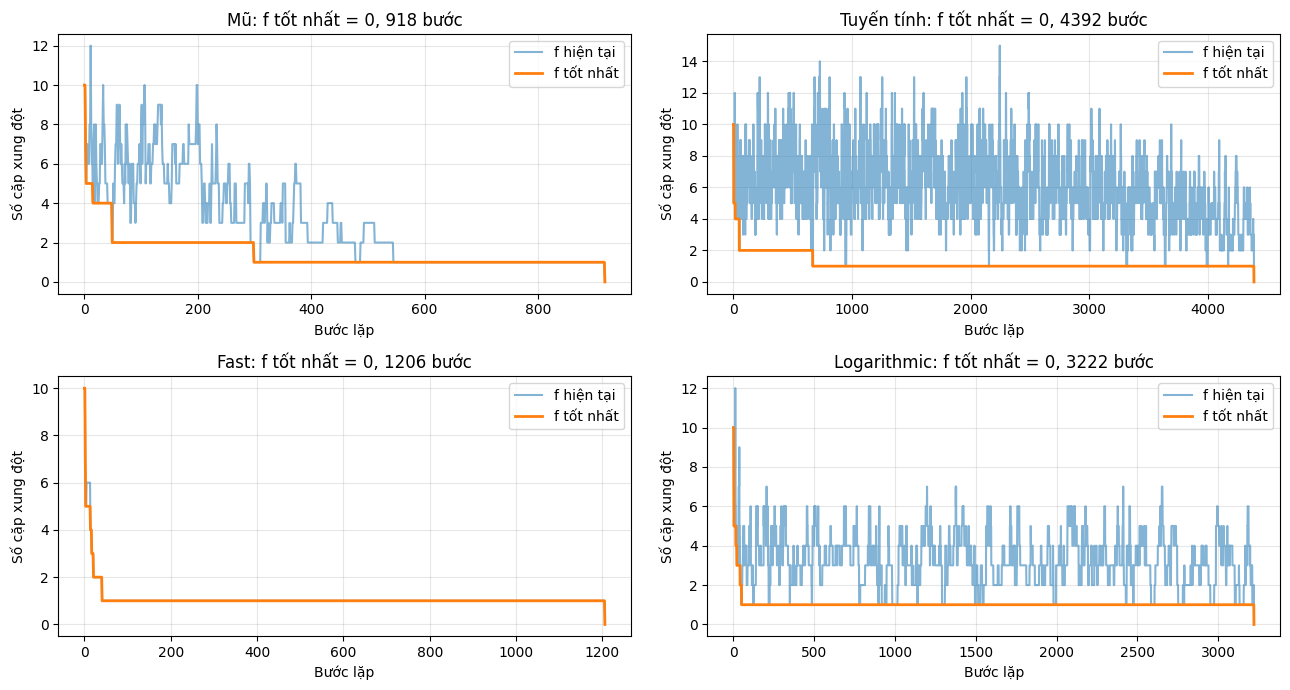

In [9]:
from pathlib import Path
import sys

lab_directory = next(
    directory for directory in [Path.cwd(), Path.cwd() / 'weekly assignments/lab03 - local search']
    if (directory / 'n_queens_sa.py').is_file()
)
if str(lab_directory) not in sys.path:
    sys.path.insert(0, str(lab_directory))
from n_queens_sa import simulated_annealing as anneal_queens
from n_queens_sa import conflicts as sa_conflicts

example_start = np.random.default_rng(2026).integers(0, 8, size=8)
assert conflicts(example_start) == sa_conflicts(example_start)
example_schedules = {
    'Mũ': lambda t: 5.0 * 0.995**t,
    'Tuyến tính': lambda t: 5.0 - (5.0 / 5001) * t,
    'Fast': lambda t: 5.0 / (1 + t),
    'Logarithmic': lambda t: 5.0 / np.log1p(t),
}
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (name, schedule) in zip(axes.flat, example_schedules.items()):
    result = anneal_queens(example_start, schedule, max_steps=5000, seed=2027)
    assert result['best_f'] == conflicts(result['best_board'])
    ax.plot(result['current_history'], alpha=0.55, label='f hiện tại')
    ax.plot(result['best_history'], linewidth=2, label='f tốt nhất')
    ax.set_title(f"{name}: f tốt nhất = {result['best_f']}, {result['steps']} bước")
    ax.set_xlabel('Bước lặp')
    ax.set_ylabel('Số cặp xung đột')
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()

**Đọc đồ thị:** Đường giá trị hiện tại có thể tăng khi SA chấp nhận bước xấu, còn đường giá trị tốt nhất không tăng. Đường kết thúc sớm khi đã tìm được 0 xung đột. Một lần chạy chỉ minh họa quá trình tìm kiếm; dùng bảng thí nghiệm lặp trong Bài 5 để đánh giá tỷ lệ thành công và thời gian.

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

### Bài 8 — Quy trình so sánh

Chạy **100 lần** trên mỗi n = 4 và n = 8 theo Task 6. Các thuật toán trong cùng lần thử dùng cùng bàn cờ ban đầu và seed. Mỗi lần có tối đa **5.000 đánh giá hàm mục tiêu**, gồm bàn cờ ban đầu. SA dùng hàm ở Bài 4–5, T(t) = 5 × 0.995ᵗ; tối đa 4.999 bước vì mỗi bước tính f một lần. Dừng sớm khi f = 0; HC còn có điều kiện cực tiểu/kiên nhẫn đã mô tả. Không khởi động lại trong bảng bốn thuật toán của Task 6.

Đo `perf_counter` quanh thuật toán, không tính sinh bàn cờ, vẽ hình và tổng hợp bảng. Báo trung bình thời gian, f tốt nhất và tỷ lệ đạt f = 0; ghi số đánh giá để thấy công việc thực dùng. Seed bàn cờ là `80000 + 1000*n + trial`, seed thuật toán là `90000 + 1000*n + trial`.

In [10]:
import pandas as pd
from time import perf_counter
from IPython.display import display, Markdown

def queens_sa_for_comparison(board, max_evals=5000, seed=0):
    run = anneal_queens(board, lambda t: 5.0 * 0.995**t,
                        max_steps=max_evals - 1, seed=seed)
    run['evaluations'] = run['steps'] + 1
    return run

queens_algorithms = {
    'Steepest HC': queens_steepest,
    'Stochastic HC': queens_stochastic,
    'First-choice HC': queens_first_choice,
    'SA': queens_sa_for_comparison,
}
queen_records = []
queen_runs = {}

def measure_queens(n, trial, names):
    seed = 80000 + 1000 * n + trial
    board = np.random.default_rng(seed).integers(0, n, size=n)
    untouched = board.copy()
    shift = trial % len(names)
    for name in names[shift:] + names[:shift]:
        started = perf_counter()
        run = queens_algorithms[name](board, max_evals=5000, seed=seed + 10000)
        milliseconds = (perf_counter() - started) * 1000
        assert run['best_f'] == conflicts(run['best_board'])
        assert np.array_equal(board, untouched)
        assert run['evaluations'] <= 5000
        assert np.all(np.diff(run['best_history']) <= 0)
        queen_runs[n, trial, name] = run
        queen_records.append({'n': n, 'Thuật toán': name, 'f': run['best_f'],
                              'ms': milliseconds, 'Đánh giá': run['evaluations']})

for n in [4, 8]:
    for trial in range(100):
        measure_queens(n, trial, list(queens_algorithms))

queen_results = pd.DataFrame(queen_records)
queen_comparison = queen_results.groupby(['n', 'Thuật toán'], sort=False).agg(
    so_lan=('f', 'size'), thoi_gian_ms_TB=('ms', 'mean'), f_TB=('f', 'mean'),
    thanh_cong_phan_tram=('f', lambda values: 100 * (values == 0).mean()),
    danh_gia_TB=('Đánh giá', 'mean'),
)
display(queen_comparison.round(3))

so_lan  thoi_gian_ms_TB  f_TB  thanh_cong_phan_tram  \
n Thuật toán                                                             
4 Steepest HC         100            0.798  0.62                  45.0   
  Stochastic HC       100            0.928  0.84                  29.0   
  First-choice HC     100            2.147  0.81                  35.0   
  SA                  100            6.748  0.00                 100.0   
8 Steepest HC         100            9.179  1.29                   8.0   
  Stochastic HC       100           11.797  1.17                  18.0   
  First-choice HC     100           16.857  1.36                  15.0   
  SA                  100           84.833  0.04                  96.0   

                   danh_gia_TB  
n Thuật toán                    
4 Steepest HC            28.00  
  Stochastic HC          33.40  
  First-choice HC        49.80  
  SA                    103.73  
8 Steepest HC           232.28  
  Stochastic HC         327.48  
  First-choice HC       302.80  
  SA                   1215.45

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

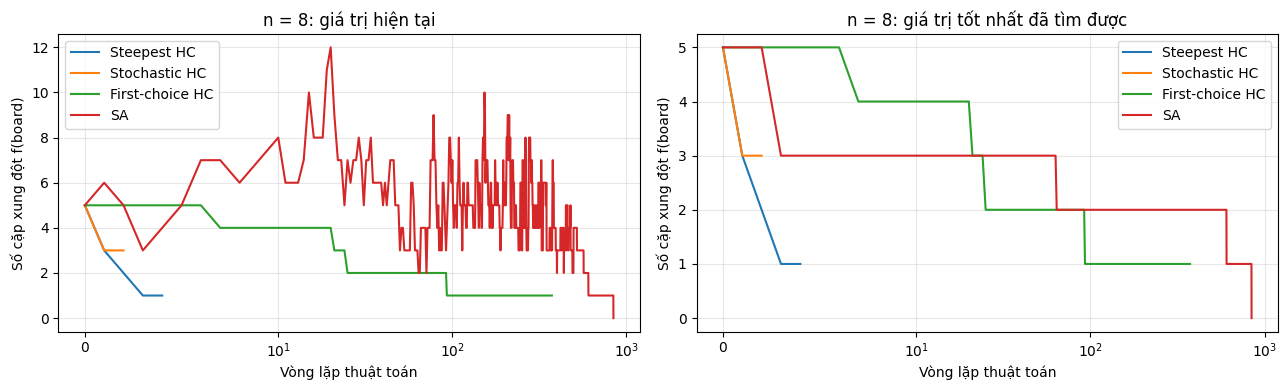

- n = 4, **Steepest HC**: f trung bình 0.62, giải được 45%, thời gian 0.80 ms.
- n = 4, **Stochastic HC**: f trung bình 0.84, giải được 29%, thời gian 0.93 ms.
- n = 4, **First-choice HC**: f trung bình 0.81, giải được 35%, thời gian 2.15 ms.
- n = 4, **SA**: f trung bình 0.00, giải được 100%, thời gian 6.75 ms.
- n = 8, **Steepest HC**: f trung bình 1.29, giải được 8%, thời gian 9.18 ms.
- n = 8, **Stochastic HC**: f trung bình 1.17, giải được 18%, thời gian 11.80 ms.
- n = 8, **First-choice HC**: f trung bình 1.36, giải được 15%, thời gian 16.86 ms.
- n = 8, **SA**: f trung bình 0.04, giải được 96%, thời gian 84.83 ms.

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in queens_algorithms:
    run = queen_runs[8, 0, name]  # cùng bàn cờ, cùng trial; không chọn lần tốt nhất
    axes[0].plot(run['current_history'], label=name)
    axes[1].plot(run['best_history'], label=name)
for ax in axes:
    ax.set_xscale('symlog', linthresh=10)
    ax.set_xlabel('Vòng lặp thuật toán')
    ax.set_ylabel('Số cặp xung đột f(board)')
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_title('n = 8: giá trị hiện tại')
axes[1].set_title('n = 8: giá trị tốt nhất đã tìm được')
fig.tight_layout()
plt.show()

notes = []
for n in [4, 8]:
    for name in queens_algorithms:
        row = queen_comparison.loc[n, name]
        notes.append(f'- n = {n}, **{name}**: f trung bình {row.f_TB:.2f}, '
                     f'giải được {row.thanh_cong_phan_tram:.0f}%, '
                     f'thời gian {row.thoi_gian_ms_TB:.2f} ms.')
display(Markdown('\n'.join(notes)))

**Nhận xét hội tụ:** Steepest thường giảm nhanh ban đầu, nhưng dừng khi toàn bộ lân cận không còn bước giảm f. Stochastic có thể giảm chậm hơn vì không luôn chọn bước tốt nhất. First-choice có các đoạn nằm ngang do lấy mẫu hàng xóm không cải thiện, rồi dừng theo kiên nhẫn nếu mắc kẹt. SA có thể tăng f hiện tại để thoát cực trị; f tốt nhất không tăng. Tỷ lệ thất bại trong bảng cho thấy mức mắc kẹt trong ngân sách đã chọn.

Trục x dùng thang symlog (tuyến tính ở các bước đầu, log ở các bước lớn) để thấy cả cải thiện ban đầu lẫn đoạn chạy dài. Một vòng Steepest/Stochastic đánh giá cả lân cận; một vòng First-choice/SA chỉ thử một hàng xóm. Vì vậy trục vòng lặp mô tả hành vi tìm kiếm, không biểu diễn cùng chi phí tính toán. Dùng thời gian và số đánh giá trong bảng để so sánh chi phí. Đường kết thúc sớm không đồng nghĩa đã giải được: cần xem f cuối có bằng 0 hay không.

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

Khảo sát hai thuật toán **Steepest HC và First-choice HC** trên n = 4, 8, 12, 16, 20. Dùng 20 lần mỗi cỡ; với n = 4,8 lấy 20 lần đầu từ thí nghiệm trên, không chạy lại. Ngân sách và quy tắc dừng giữ nguyên. Ước lượng độ dốc p của T ≈ c·nᵖ trên năm kích thước chỉ là mô tả thực nghiệm, vì số vòng lặp và điều kiện dừng cũng thay đổi theo n.

thoi_gian_ms_TB  f_TB  thanh_cong_phan_tram
n  Thuật toán                                                  
4  Steepest HC                0.612  0.65                  40.0
   First-choice HC            2.759  1.15                  10.0
8  Steepest HC                9.256  1.30                   5.0
   First-choice HC           18.176  1.35                  15.0
12 Steepest HC               37.571  1.70                   5.0
   First-choice HC           48.903  1.70                   0.0
16 Steepest HC              111.399  1.90                   0.0
   First-choice HC          139.231  2.05                  10.0
20 Steepest HC              254.335  2.45                   0.0
   First-choice HC          206.455  2.60                   0.0

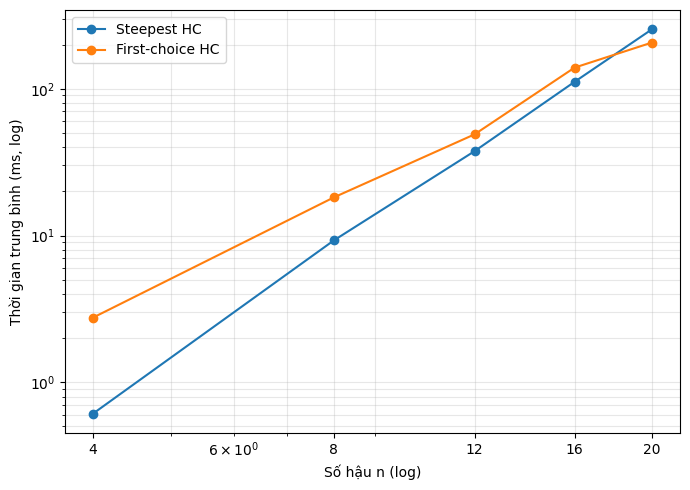

**Độ dốc thực nghiệm:** Steepest HC: p ≈ 3.73, First-choice HC: p ≈ 2.72. Ở n = 20, **First-choice HC** có thời gian trung bình thấp hơn; cần đối chiếu f và tỷ lệ thành công trong bảng trước khi đánh giá hiệu quả tổng thể.

In [12]:
scaling_names = ['Steepest HC', 'First-choice HC']
for n in [12, 16, 20]:
    for trial in range(20):
        measure_queens(n, trial, scaling_names)

queen_all_results = pd.DataFrame(queen_records)
scaling_results = queen_all_results[
    queen_all_results['Thuật toán'].isin(scaling_names)
].copy()
# n = 4,8 chỉ dùng 20 lần đầu của từng thuật toán.
scaling_results = scaling_results.groupby(['n', 'Thuật toán'], sort=False).head(20)
scaling_summary = scaling_results.groupby(['n', 'Thuật toán'], sort=False).agg(
    thoi_gian_ms_TB=('ms', 'mean'), f_TB=('f', 'mean'),
    thanh_cong_phan_tram=('f', lambda values: 100 * (values == 0).mean()),
)
display(scaling_summary.round(3))
plt.figure(figsize=(7, 5))
slopes = {}
for name in scaling_names:
    subset = scaling_summary.xs(name, level='Thuật toán').sort_index()
    plt.loglog(subset.index, subset.thoi_gian_ms_TB, 'o-', label=name)
    slopes[name] = np.polyfit(np.log(subset.index), np.log(subset.thoi_gian_ms_TB), 1)[0]
plt.xticks([4, 8, 12, 16, 20], ['4', '8', '12', '16', '20'])
plt.xlabel('Số hậu n (log)')
plt.ylabel('Thời gian trung bình (ms, log)')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

largest = scaling_summary.loc[20]
fastest = largest.thoi_gian_ms_TB.idxmin()
display(Markdown(
    '**Độ dốc thực nghiệm:** ' + ', '.join(f'{name}: p ≈ {value:.2f}' for name, value in slopes.items())
    + f'. Ở n = 20, **{fastest}** có thời gian trung bình thấp hơn; '
    'cần đối chiếu f và tỷ lệ thành công trong bảng trước khi đánh giá hiệu quả tổng thể.'
))

**Phân tích:** Hàm đếm xung đột O(n), lân cận chuẩn có n(n−1) phần tử. Một vòng Steepest hoặc Stochastic có chi phí O(n³); một bước First-choice có chi phí O(n) do lấy mẫu trực tiếp một cột/hàng và chỉ tính f một lần. First-choice tránh việc tính f cho toàn bộ lân cận, nhưng vẫn có thể không giải được bài toán.

Độ dốc từ năm điểm không chứng minh Big O của toàn bộ tìm kiếm. Các thuật toán dừng ở nghiệm, cực tiểu, giới hạn kiên nhẫn hoặc ngân sách; vì vậy thời gian thấp cũng có thể đi cùng nghiệm kém hơn.

## Bài 8 — Thử toán tử di chuyển khác (phần nâng cao)

So sánh First-choice với hai toán tử trên n = 8,12, mỗi cấu hình 30 lần, cùng bàn cờ và seed, tối đa 5.000 đánh giá:

- **Chuyển hàng bất kỳ:** n(n−1) hàng xóm.
- **Một bước lên/xuống:** chuyển hậu sang hàng kề nếu còn trong bàn cờ; số hàng xóm từ n đến 2n (với n ≥ 2), nhỏ hơn đáng kể.

Toán tử một bước hạn chế phạm vi cải thiện mỗi lần và có thể mắc kẹt ở cực tiểu mà toán tử chuyển hàng bất kỳ còn thoát được. Kiểm tra ảnh hưởng qua f, tỷ lệ thành công và thời gian, không chỉ qua kích thước lân cận.


In [13]:
operator_records = []
for n in [8, 12]:
    for trial in range(30):
        seed = 88000 + 100 * n + trial
        start = np.random.default_rng(seed).integers(0, n, size=n)
        for operator in ['any', 'adjacent']:
            started = perf_counter()
            run = queens_hc(start, 'first', 5000, seed + 1, operator)
            milliseconds = (perf_counter() - started) * 1000
            assert run['best_f'] == conflicts(run['best_board'])
            operator_records.append({'n': n, 'Toán tử': operator, 'f': run['best_f'], 'ms': milliseconds})
operator_summary = pd.DataFrame(operator_records).groupby(['n', 'Toán tử']).agg(
    f_TB=('f', 'mean'), thanh_cong_phan_tram=('f', lambda values: 100 * (values == 0).mean()),
    thoi_gian_ms_TB=('ms', 'mean'),
)
display(operator_summary.round(3))

f_TB  thanh_cong_phan_tram  thoi_gian_ms_TB
n  Toán tử                                               
8  adjacent  3.633                 3.333            6.802
   any       1.200                20.000           23.228
12 adjacent  5.633                 0.000            8.967
   any       1.667                 3.333           42.467

**Kết luận:** Lân cận nhỏ hơn giúp xét ít lựa chọn, nhưng không tự bảo đảm tìm kiếm hiệu quả hơn. Toán tử kề có thể dừng sớm ở f > 0; bảng trên cho phép nhận ra việc chạy nhanh do dừng sớm hay do tìm được lời giải. Đã hoàn thành so sánh n = 4,8, đồ thị hội tụ, khảo sát mở rộng n = 4,8,12,16,20 và thử toán tử khác theo Bài 8.

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [14]:
# Code and description go here